In [ ]:
#!/usr/bin/env python3

# %% [markdown]
# # Ground-truth bounding-box ellipsoid versus clinical prostate volume
#
# This notebook tests whether applying the clinical ellipsoid formula to dimensions
# derived from a whole-gland segmentation agrees with the manual clinical ellipsoid
# volume better than direct voxel-count volume.
#
# The primary bounding box uses the central 99.9% of foreground coordinates along
# each image axis (0.05th to 99.95th percentiles). Exact min-max dimensions are
# retained as a sensitivity analysis.

In [ ]:
from __future__ import annotations

import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import pandas as pd
import pingouin as pg
from scipy import stats

try:
    from IPython.display import display
except ImportError:  # pragma: no cover - plain Python fallback
    def display(*objects: object) -> None:
        for obj in objects:
            print(obj)


REPO_ROOT = Path(__file__).resolve().parents[1]
MASK_ROOT = REPO_ROOT / "data/raw/github/prostatex_masks"
INDEX_PATH = MASK_ROOT / "index.csv"
PICAI_LABELS = REPO_ROOT / "data/raw/zenodo/picai/picai_labels"
MAPPING_PATH = PICAI_LABELS / "additional_resources/ProstateX-mapping.json"
MARKSHEET_PATH = PICAI_LABELS / "clinical_information/marksheet.csv"

LOWER_QUANTILE = 0.0005
UPPER_QUANTILE = 0.9995
BOOTSTRAP_ITERATIONS = 20_000
RANDOM_SEED = 20260714

MEASUREMENT_LABELS = {
    "manual_volume_ml": "Manual marksheet",
    "voxel_volume_ml": "Voxel-count volume",
    "ellipsoid_999_ml": "99.9% ellipsoid",
    "ellipsoid_minmax_ml": "Min-max ellipsoid",
}
PRIMARY_MEASUREMENTS = [
    "manual_volume_ml",
    "ellipsoid_999_ml",
    "voxel_volume_ml",
]
PAIR_SPECS = [
    ("manual_volume_ml", "ellipsoid_999_ml"),
    ("manual_volume_ml", "voxel_volume_ml"),
    ("ellipsoid_999_ml", "voxel_volume_ml"),
]

plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 9,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "figure.dpi": 150,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

 ## Cohort matching

 `ProstateX-mapping.json` keys include acquisition dates that are absent from the
 mask index. ProstateX IDs with more than one mapping are excluded rather than
 assigning an arbitrary PI-CAI study.

In [ ]:
cases = pd.read_csv(INDEX_PATH)
assert not cases["ID"].duplicated().any(), "Duplicate IDs in the ProstateX mask index"

with MAPPING_PATH.open() as file:
    mapping = json.load(file)

mapping_df = pd.DataFrame(
    [(key.split("_")[0], value) for key, value in mapping.items()],
    columns=["ID", "picai_key"],
)
ambiguous_ids = mapping_df.loc[
    mapping_df["ID"].duplicated(keep=False), "ID"
].unique()
mapping_df = mapping_df.loc[~mapping_df["ID"].isin(ambiguous_ids)].copy()
mapping_df[["patient_id", "study_id"]] = (
    mapping_df["picai_key"].str.split("_", expand=True).astype(int)
)

marksheet = pd.read_csv(MARKSHEET_PATH)
cohort = cases.merge(
    mapping_df[["ID", "patient_id", "study_id"]], on="ID", how="left"
).merge(marksheet, on=["patient_id", "study_id"], how="left")

assert not cohort["ID"].duplicated().any(), "Clinical merge produced duplicate IDs"
matched = cohort.dropna(subset=["prostate_volume"]).copy()
matched = matched.loc[np.isfinite(matched["prostate_volume"])]
matched = matched.loc[matched["prostate_volume"] > 0].reset_index(drop=True)

print(f"ProstateX masks: {len(cases)}")
print(f"Ambiguous mappings excluded: {len(ambiguous_ids)}")
print(f"Cases with a positive clinical prostate volume: {len(matched)}")

ProstateX masks: 204
Ambiguous mappings excluded: 1
Cases with a positive clinical prostate volume: 190


 ## Segmentation-derived dimensions and volumes

 Coordinate differences describe distances between voxel centers. Adding one voxel
 before multiplying by spacing gives the inclusive occupied width. For the quantile
 box, NumPy's linear quantile interpolation is used before adding one voxel width.
 The three axes are labeled by their anatomical orientation from the NIfTI affine.

In [ ]:
def physical_spacing_mm(img: nib.spatialimages.SpatialImage) -> np.ndarray:
    """Return voxel-axis lengths and reject sheared image geometry."""
    basis = np.asarray(img.affine[:3, :3], dtype=float)
    spacing = np.linalg.norm(basis, axis=0)
    if spacing.shape != (3,) or not np.all(np.isfinite(spacing)) or np.any(spacing <= 0):
        raise ValueError(f"Invalid physical spacing: {spacing}")

    directions = basis / spacing
    if not np.allclose(directions.T @ directions, np.eye(3), atol=1e-4):
        raise ValueError("Ellipsoid dimensions require orthogonal voxel axes")
    return spacing


def inclusive_extent_mm(
    coordinates: np.ndarray,
    spacing_mm: np.ndarray,
    lower_quantile: float = 0.0,
    upper_quantile: float = 1.0,
) -> np.ndarray:
    """Calculate inclusive per-axis extents from foreground voxel centers."""
    if coordinates.ndim != 2 or coordinates.shape[1] != 3 or len(coordinates) == 0:
        raise ValueError("Expected non-empty N x 3 foreground coordinates")
    if not 0 <= lower_quantile < upper_quantile <= 1:
        raise ValueError("Quantiles must satisfy 0 <= lower < upper <= 1")

    lower, upper = np.quantile(
        coordinates, [lower_quantile, upper_quantile], axis=0, method="linear"
    )
    return (upper - lower + 1.0) * spacing_mm


def ellipsoid_volume_ml(dimensions_mm: np.ndarray) -> float:
    """Calculate pi/6 * length * width * height and convert mm3 to mL."""
    dimensions_mm = np.asarray(dimensions_mm, dtype=float)
    if dimensions_mm.shape != (3,) or np.any(dimensions_mm <= 0):
        raise ValueError(f"Invalid ellipsoid dimensions: {dimensions_mm}")
    return float(np.prod(dimensions_mm) * np.pi / 6.0 / 1000.0)


# Small deterministic checks make the inclusive-extent convention explicit.
synthetic_coordinates = np.argwhere(np.ones((4, 6, 8), dtype=bool))
synthetic_spacing = np.array([0.5, 1.0, 2.0])
synthetic_dimensions = inclusive_extent_mm(
    synthetic_coordinates, synthetic_spacing
)
assert np.allclose(synthetic_dimensions, [2.0, 6.0, 16.0])
assert math.isclose(
    ellipsoid_volume_ml(synthetic_dimensions),
    2.0 * 6.0 * 16.0 * np.pi / 6.0 / 1000.0,
)

In [ ]:
volume_rows: list[dict[str, float | str]] = []
observed_axis_codes: set[tuple[str, str, str]] = set()

for row in matched.itertuples(index=False):
    mask_path = MASK_ROOT / row.label_wg
    if not mask_path.is_file():
        raise FileNotFoundError(mask_path)

    img = nib.load(mask_path)
    if len(img.shape) != 3:
        raise ValueError(f"Expected a 3D mask for {row.ID}, got {img.shape}")

    mask = np.asarray(img.dataobj) > 0
    coordinates = np.argwhere(mask)
    if len(coordinates) == 0:
        raise ValueError(f"Empty whole-gland mask for {row.ID}")

    spacing_mm = physical_spacing_mm(img)
    axis_codes = tuple(str(code) for code in nib.aff2axcodes(img.affine))
    observed_axis_codes.add(axis_codes)
    if axis_codes != ("L", "A", "S"):
        raise ValueError(f"Unexpected axis ordering for {row.ID}: {axis_codes}")

    dimensions_999 = inclusive_extent_mm(
        coordinates, spacing_mm, LOWER_QUANTILE, UPPER_QUANTILE
    )
    dimensions_minmax = inclusive_extent_mm(coordinates, spacing_mm)
    voxel_volume_ml = float(mask.sum() * np.prod(spacing_mm) / 1000.0)

    volume_rows.append(
        {
            "ID": row.ID,
            "manual_volume_ml": float(row.prostate_volume),
            "voxel_volume_ml": voxel_volume_ml,
            "ellipsoid_999_ml": ellipsoid_volume_ml(dimensions_999),
            "ellipsoid_minmax_ml": ellipsoid_volume_ml(dimensions_minmax),
            "lr_999_mm": float(dimensions_999[0]),
            "ap_999_mm": float(dimensions_999[1]),
            "si_999_mm": float(dimensions_999[2]),
            "lr_minmax_mm": float(dimensions_minmax[0]),
            "ap_minmax_mm": float(dimensions_minmax[1]),
            "si_minmax_mm": float(dimensions_minmax[2]),
        }
    )

analysis = pd.DataFrame(volume_rows)
numeric_columns = analysis.columns.drop("ID")
assert len(analysis) == len(matched)
assert analysis["ID"].is_unique
assert np.isfinite(analysis[numeric_columns].to_numpy()).all()
assert (analysis[numeric_columns] > 0).all().all()

print(f"Observed NIfTI axis codes: {sorted(observed_axis_codes)}")
display(analysis.head())

Observed NIfTI axis codes: [('L', 'A', 'S')]


,ID,manual_volume_ml,voxel_volume_ml,ellipsoid_999_ml,ellipsoid_minmax_ml,lr_999_mm,ap_999_mm,si_999_mm,lr_minmax_mm,ap_minmax_mm,si_minmax_mm
0,ProstateX-0000,52.0,45.158247,49.279019,53.909726,62.000002,45.999999,32.999998,65.000002,47.999999,32.999998
1,ProstateX-0001,28.0,33.600750,37.695970,39.875843,52.000000,35.500000,39.000000,53.500000,36.500000,39.000000
2,ProstateX-0002,39.0,28.818000,27.214046,28.639544,50.000000,31.500000,33.000000,51.000000,32.500000,33.000000
3,ProstateX-0003,122.0,136.919996,123.445738,132.804543,74.000000,59.000000,53.999999,77.000000,61.000000,53.999999
4,ProstateX-0004,146.0,160.324875,148.157510,157.657686,65.500000,60.000000,72.000000,68.000000,61.500000,72.000000


 ## Descriptive comparison of bounding-box definitions

In [ ]:
dimension_summary = analysis[
    [
        "lr_999_mm",
        "ap_999_mm",
        "si_999_mm",
        "lr_minmax_mm",
        "ap_minmax_mm",
        "si_minmax_mm",
    ]
].describe(percentiles=[0.025, 0.25, 0.5, 0.75, 0.975]).T

box_sensitivity = pd.DataFrame(
    {
        "99.9% ellipsoid (mL)": analysis["ellipsoid_999_ml"],
        "Min-max ellipsoid (mL)": analysis["ellipsoid_minmax_ml"],
    }
)
box_sensitivity["Min-max minus 99.9% (mL)"] = (
    box_sensitivity["Min-max ellipsoid (mL)"]
    - box_sensitivity["99.9% ellipsoid (mL)"]
)
box_sensitivity["Min-max / 99.9%"] = (
    box_sensitivity["Min-max ellipsoid (mL)"]
    / box_sensitivity["99.9% ellipsoid (mL)"]
)

display(dimension_summary)
display(box_sensitivity.describe().T)

,count,mean,std,min,2.5%,25%,50%,75%,97.5%,max
lr_999_mm,190.0,55.596723,7.449535,39.000001,43.0875,49.625000,55.500000,60.374999,74.412500,79.200003
ap_999_mm,190.0,46.740158,9.049048,27.500000,32.2250,40.575001,46.250000,52.000000,68.572500,74.400003
si_999_mm,190.0,47.423684,9.964658,27.000000,30.0000,41.999999,45.000002,54.000000,69.825002,80.999999
lr_minmax_mm,190.0,57.327763,7.828512,40.000001,44.4500,51.000000,57.000000,62.000000,77.137500,82.200003
ap_minmax_mm,190.0,48.343882,9.444669,28.000000,33.5875,41.625001,48.000000,53.500001,71.572500,77.100003
si_minmax_mm,190.0,47.423684,9.964658,27.000000,30.0000,41.999999,45.000002,54.000000,69.825002,80.999999


,count,mean,std,min,25%,50%,75%,max
99.9% ellipsoid (mL),190.0,69.010828,35.525336,16.508846,44.041399,61.806712,84.614373,243.282563
Min-max ellipsoid (mL),190.0,73.742324,38.390592,17.307427,46.291370,65.809691,91.131224,264.864081
Min-max minus 99.9% (mL),190.0,4.731496,3.103525,0.693496,2.543119,3.984914,6.392062,21.581518
Min-max / 99.9%,190.0,1.065912,0.018538,1.021098,1.052446,1.065115,1.075925,1.139526


 ## Full pairwise agreement statistics

 ICC(A,1) is the two-way random-effects, absolute-agreement, single-measure ICC.
 For every ordered pair, differences are calculated as the second measurement
 minus the first. The bias test is a two-sided one-sample t-test of mean difference
 equal to zero; its p-values are Holm-adjusted across the three comparisons.

In [ ]:
def holm_adjust(p_values: np.ndarray) -> np.ndarray:
    """Return Holm-adjusted p-values in their original order."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    ordered = p_values[order]
    adjusted_ordered = np.maximum.accumulate(
        (len(p_values) - np.arange(len(p_values))) * ordered
    )
    adjusted = np.empty_like(adjusted_ordered)
    adjusted[order] = np.minimum(adjusted_ordered, 1.0)
    return adjusted


def matched_rank_biserial(differences: np.ndarray) -> float:
    """Calculate signed matched-pairs rank-biserial correlation."""
    differences = np.asarray(differences, dtype=float)
    nonzero = differences[differences != 0]
    if len(nonzero) == 0:
        return 0.0
    ranks = stats.rankdata(np.abs(nonzero), method="average")
    positive = float(ranks[nonzero > 0].sum())
    negative = float(ranks[nonzero < 0].sum())
    return (positive - negative) / float(ranks.sum())


def icc_absolute_agreement(first: pd.Series, second: pd.Series) -> float:
    long = pd.DataFrame(
        {
            "case": np.repeat(np.arange(len(first)), 2),
            "rater": np.tile(["first", "second"], len(first)),
            "volume": np.column_stack([first.to_numpy(), second.to_numpy()]).ravel(),
        }
    )
    icc = pg.intraclass_corr(
        data=long, targets="case", raters="rater", ratings="volume"
    )
    return float(icc.set_index("Type").loc["ICC(A,1)", "ICC"])


def agreement_statistics(
    first: pd.Series, second: pd.Series
) -> dict[str, float | int]:
    first_values = first.to_numpy(dtype=float)
    second_values = second.to_numpy(dtype=float)
    differences = second_values - first_values
    n = len(differences)
    bias = float(differences.mean())
    difference_sd = float(differences.std(ddof=1))
    sem = difference_sd / np.sqrt(n)
    ci_delta = float(stats.t.ppf(0.975, df=n - 1) * sem)
    bias_test = stats.ttest_1samp(differences, popmean=0.0)
    pearson = stats.pearsonr(first_values, second_values)

    return {
        "n": n,
        "bias_ml": bias,
        "bias_ci_lower_ml": bias - ci_delta,
        "bias_ci_upper_ml": bias + ci_delta,
        "bias_p": float(bias_test.pvalue),
        "loa_lower_ml": bias - 1.96 * difference_sd,
        "loa_upper_ml": bias + 1.96 * difference_sd,
        "mae_ml": float(np.mean(np.abs(differences))),
        "rmse_ml": float(np.sqrt(np.mean(differences**2))),
        "pearson_r": float(pearson.statistic),
        "pearson_p": float(pearson.pvalue),
        "icc_a1": icc_absolute_agreement(first, second),
    }


pair_labels = {
    pair: f"{MEASUREMENT_LABELS[pair[1]]} minus {MEASUREMENT_LABELS[pair[0]]}"
    for pair in PAIR_SPECS
}
agreement = pd.DataFrame(
    {
        pair_labels[(first, second)]: agreement_statistics(
            analysis[first], analysis[second]
        )
        for first, second in PAIR_SPECS
    }
).T
agreement["bias_p_holm"] = holm_adjust(agreement["bias_p"].to_numpy())

matrix_labels = [MEASUREMENT_LABELS[column] for column in PRIMARY_MEASUREMENTS]
pearson_matrix = pd.DataFrame(
    np.eye(len(PRIMARY_MEASUREMENTS)), index=matrix_labels, columns=matrix_labels
)
icc_matrix = pearson_matrix.copy()
for first, second in PAIR_SPECS:
    first_label = MEASUREMENT_LABELS[first]
    second_label = MEASUREMENT_LABELS[second]
    pair_row = agreement.loc[pair_labels[(first, second)]]
    pearson_matrix.loc[first_label, second_label] = pair_row["pearson_r"]
    pearson_matrix.loc[second_label, first_label] = pair_row["pearson_r"]
    icc_matrix.loc[first_label, second_label] = pair_row["icc_a1"]
    icc_matrix.loc[second_label, first_label] = pair_row["icc_a1"]

assert np.allclose(pearson_matrix, pearson_matrix.T)
assert np.allclose(icc_matrix, icc_matrix.T)
assert np.allclose(np.diag(pearson_matrix), 1.0)
assert np.allclose(np.diag(icc_matrix), 1.0)
assert (agreement["n"] == len(analysis)).all()

descriptive_summary = analysis[PRIMARY_MEASUREMENTS].agg(
    ["count", "mean", "std", "median", "min", "max"]
).T
descriptive_summary["q1"] = analysis[PRIMARY_MEASUREMENTS].quantile(0.25)
descriptive_summary["q3"] = analysis[PRIMARY_MEASUREMENTS].quantile(0.75)
descriptive_summary["iqr"] = (
    descriptive_summary["q3"] - descriptive_summary["q1"]
)
descriptive_summary.index = matrix_labels
descriptive_summary = descriptive_summary[
    ["count", "mean", "std", "median", "q1", "q3", "iqr", "min", "max"]
]

display(descriptive_summary)
display(agreement)
print("Pearson correlation")
display(pearson_matrix)
print("ICC(A,1), absolute agreement")
display(icc_matrix)

,count,mean,std,median,q1,q3,iqr,min,max
Manual marksheet,190.0,69.358947,38.968579,61.500000,43.250000,83.750000,40.500000,17.000000,308.000000
99.9% ellipsoid,190.0,69.010828,35.525336,61.806712,44.041399,84.614373,40.572974,16.508846,243.282563
Voxel-count volume,190.0,66.739264,37.194310,57.347250,40.998560,83.222090,42.223531,19.527750,267.245207


,n,bias_ml,bias_ci_lower_ml,bias_ci_upper_ml,bias_p,loa_lower_ml,loa_upper_ml,mae_ml,rmse_ml,pearson_r,pearson_p,icc_a1,bias_p_holm
99.9% ellipsoid minus Manual marksheet,190.0,-0.348119,-2.341753,1.645516,0.730895,-27.653013,26.956775,9.851008,13.898719,0.934187,4.421225e-86,0.930505,0.730895
Voxel-count volume minus Manual marksheet,190.0,-2.619683,-4.592816,-0.646550,0.009535,-29.643785,24.404419,10.401184,13.998779,0.935506,7.018398e-87,0.932608,0.019070
Voxel-count volume minus 99.9% ellipsoid,190.0,-2.271564,-3.272795,-1.270333,0.000013,-15.984462,11.441333,5.573392,7.338369,0.982531,3.038729e-139,0.979681,0.000039


Pearson correlation


,Manual marksheet,99.9% ellipsoid,Voxel-count volume
Manual marksheet,1.000000,0.934187,0.935506
99.9% ellipsoid,0.934187,1.000000,0.982531
Voxel-count volume,0.935506,0.982531,1.000000


ICC(A,1), absolute agreement


,Manual marksheet,99.9% ellipsoid,Voxel-count volume
Manual marksheet,1.000000,0.930505,0.932608
99.9% ellipsoid,0.930505,1.000000,0.979681
Voxel-count volume,0.932608,0.979681,1.000000


 ## Overall and post-hoc paired measurement tests

 The Friedman test evaluates whether the three paired volume measurements have
 the same location. If interpreted post-hoc, paired Wilcoxon tests cover all three
 ordered pairs with Holm correction. Positive rank-biserial effects indicate that
 the second measurement tends to be larger than the first.

In [ ]:
friedman_result = stats.friedmanchisquare(
    *(analysis[column].to_numpy() for column in PRIMARY_MEASUREMENTS)
)

posthoc_rows: list[dict[str, float | int | str]] = []
for first, second in PAIR_SPECS:
    differences = analysis[second].to_numpy() - analysis[first].to_numpy()
    result = stats.wilcoxon(differences, alternative="two-sided", zero_method="wilcox")
    posthoc_rows.append(
        {
            "comparison": pair_labels[(first, second)],
            "n": len(differences),
            "median_difference_ml": float(np.median(differences)),
            "wilcoxon_statistic": float(result.statistic),
            "wilcoxon_p": float(result.pvalue),
            "matched_rank_biserial": matched_rank_biserial(differences),
        }
    )

posthoc = pd.DataFrame(posthoc_rows).set_index("comparison")
posthoc["wilcoxon_p_holm"] = holm_adjust(posthoc["wilcoxon_p"].to_numpy())
omnibus = pd.Series(
    {
        "n": len(analysis),
        "friedman_chi2": float(friedman_result.statistic),
        "df": len(PRIMARY_MEASUREMENTS) - 1,
        "friedman_p": float(friedman_result.pvalue),
    },
    name="Friedman omnibus test",
)

display(omnibus.to_frame())
display(posthoc)

,Friedman omnibus test
n,190.000000
friedman_chi2,12.600000
df,2.000000
friedman_p,0.001836


,n,median_difference_ml,wilcoxon_statistic,wilcoxon_p,matched_rank_biserial,wilcoxon_p_holm
comparison,,,,,,
99.9% ellipsoid minus Manual marksheet,190,0.056978,8885.0,8.048845e-01,0.020667,0.804884
Voxel-count volume minus Manual marksheet,190,-2.174251,7040.0,7.410464e-03,-0.224029,0.014821
Voxel-count volume minus 99.9% ellipsoid,190,-3.107607,5350.0,9.372159e-07,-0.410306,0.000003


 ## Primary paired hypothesis test

 The paired endpoint is:

 `|99.9% ellipsoid - manual| - |voxel volume - manual|`

 Negative values favor the segmentation-derived ellipsoid. The Wilcoxon test is
 two-sided. The matched rank-biserial effect is signed in the same direction as
 the endpoint, and the median effect receives a seeded percentile-bootstrap CI.

In [ ]:
manual = analysis["manual_volume_ml"].to_numpy()
voxel_abs_error = np.abs(analysis["voxel_volume_ml"].to_numpy() - manual)
ellipsoid_abs_error = np.abs(analysis["ellipsoid_999_ml"].to_numpy() - manual)
paired_error_delta = ellipsoid_abs_error - voxel_abs_error

wilcoxon_result = stats.wilcoxon(
    paired_error_delta, alternative="two-sided", zero_method="wilcox"
)
rng = np.random.default_rng(RANDOM_SEED)
bootstrap_medians = np.empty(BOOTSTRAP_ITERATIONS)
for iteration in range(BOOTSTRAP_ITERATIONS):
    sample = rng.choice(paired_error_delta, size=len(paired_error_delta), replace=True)
    bootstrap_medians[iteration] = np.median(sample)
bootstrap_ci = np.quantile(bootstrap_medians, [0.025, 0.975])

primary_test = pd.Series(
    {
        "n": len(paired_error_delta),
        "voxel_mae_ml": voxel_abs_error.mean(),
        "ellipsoid_999_mae_ml": ellipsoid_abs_error.mean(),
        "ellipsoid_closer_n": int((ellipsoid_abs_error < voxel_abs_error).sum()),
        "equal_error_n": int((ellipsoid_abs_error == voxel_abs_error).sum()),
        "median_paired_error_delta_ml": np.median(paired_error_delta),
        "median_delta_ci_lower_ml": bootstrap_ci[0],
        "median_delta_ci_upper_ml": bootstrap_ci[1],
        "wilcoxon_statistic": wilcoxon_result.statistic,
        "wilcoxon_p": wilcoxon_result.pvalue,
        "matched_rank_biserial": matched_rank_biserial(paired_error_delta),
    },
    name="Primary paired absolute-error test",
)
display(primary_test.to_frame())

,Primary paired absolute-error test
n,190.000000
voxel_mae_ml,10.401184
ellipsoid_999_mae_ml,9.851008
ellipsoid_closer_n,98.000000
equal_error_n,0.000000
median_paired_error_delta_ml,-0.193587
median_delta_ci_lower_ml,-1.325059
median_delta_ci_upper_ml,0.637482
wilcoxon_statistic,8248.000000
wilcoxon_p,0.277357


 ## Agreement plots

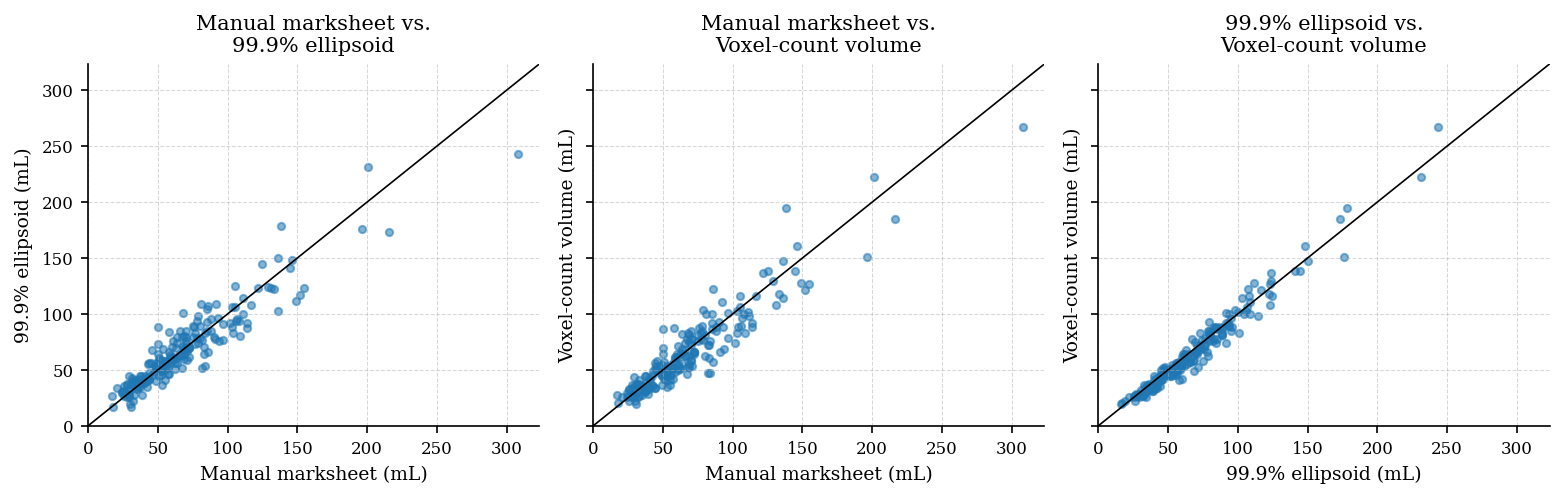

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharex=True, sharey=True)

plot_max = float(
    analysis[PRIMARY_MEASUREMENTS].to_numpy().max() * 1.05
)
for ax, (first, second) in zip(axes, PAIR_SPECS):
    ax.scatter(analysis[first], analysis[second], s=12, alpha=0.55)
    ax.plot([0, plot_max], [0, plot_max], color="black", linewidth=0.8)
    ax.set_title(f"{MEASUREMENT_LABELS[first]} vs.\n{MEASUREMENT_LABELS[second]}")
    ax.set_xlabel(f"{MEASUREMENT_LABELS[first]} (mL)")
    ax.set_ylabel(f"{MEASUREMENT_LABELS[second]} (mL)")
    ax.set_xlim(0, plot_max)
    ax.set_ylim(0, plot_max)
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)

fig.tight_layout()
plt.show()

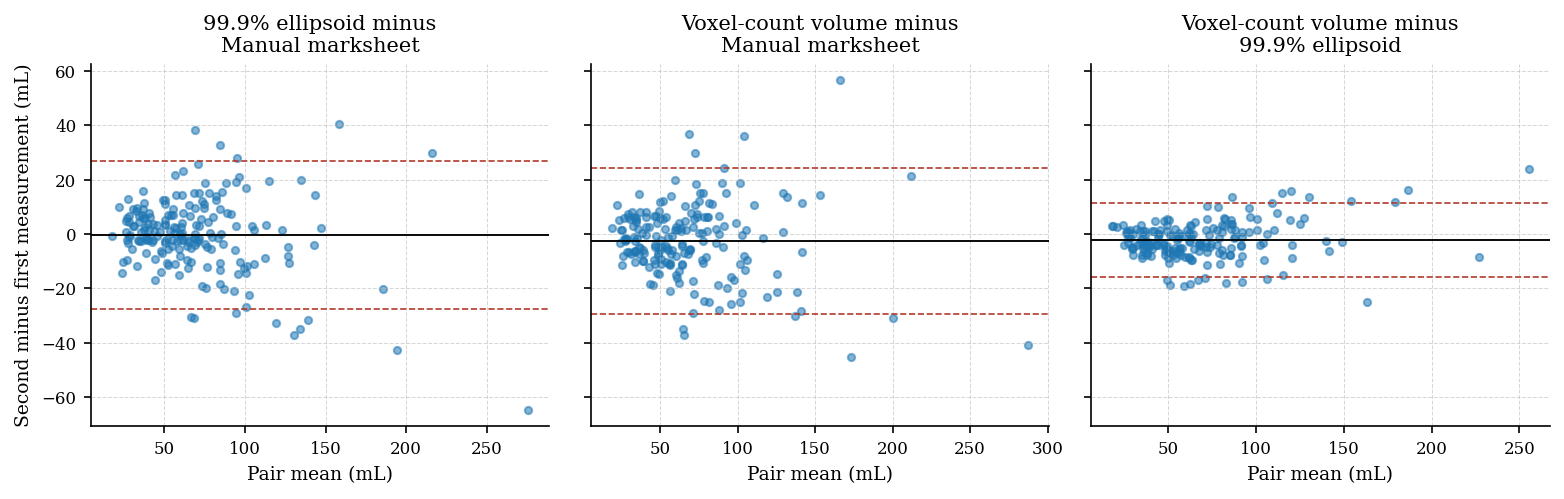

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4), sharey=True)

for ax, (first, second) in zip(axes, PAIR_SPECS):
    averages = (analysis[first] + analysis[second]) / 2.0
    differences = analysis[second] - analysis[first]
    row = agreement.loc[pair_labels[(first, second)]]

    ax.scatter(averages, differences, s=12, alpha=0.55)
    ax.axhline(row["bias_ml"], color="black", linewidth=0.9)
    ax.axhline(row["loa_lower_ml"], color="#b23a2b", linestyle="--", linewidth=0.8)
    ax.axhline(row["loa_upper_ml"], color="#b23a2b", linestyle="--", linewidth=0.8)
    ax.set_title(f"{MEASUREMENT_LABELS[second]} minus\n{MEASUREMENT_LABELS[first]}")
    ax.set_xlabel("Pair mean (mL)")
    ax.grid(True, linestyle="--", linewidth=0.5, alpha=0.5)

axes[0].set_ylabel("Second minus first measurement (mL)")
fig.tight_layout()
plt.show()

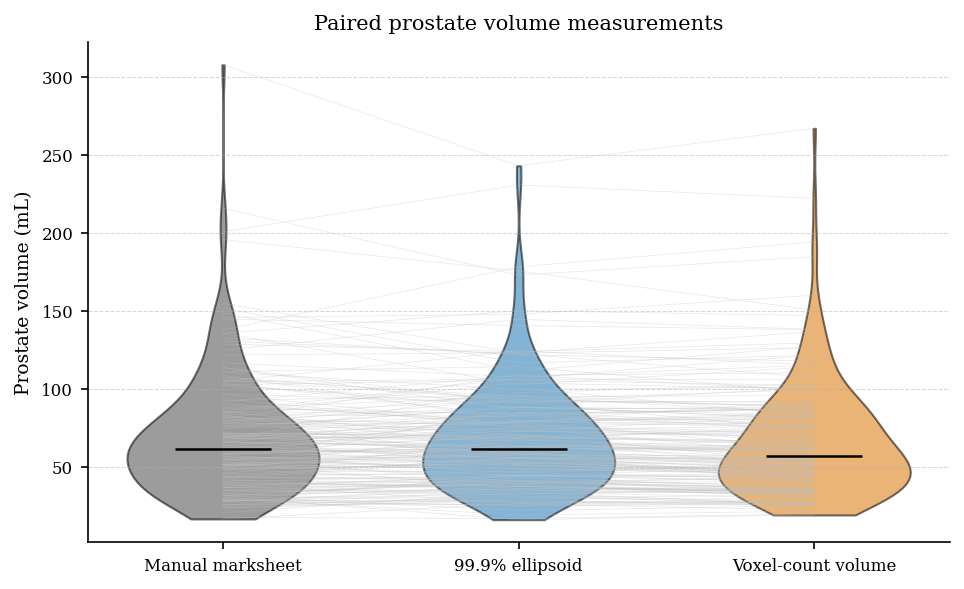

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
x_positions = np.arange(len(PRIMARY_MEASUREMENTS))
values = analysis[PRIMARY_MEASUREMENTS].to_numpy()

for case_values in values:
    ax.plot(x_positions, case_values, color="0.75", linewidth=0.35, alpha=0.35)

parts = ax.violinplot(
    [analysis[column].to_numpy() for column in PRIMARY_MEASUREMENTS],
    positions=x_positions,
    showmeans=False,
    showmedians=True,
    showextrema=False,
    widths=0.65,
)
for body, color in zip(parts["bodies"], ["#4c4c4c", "#1f77b4", "#d97706"]):
    body.set_facecolor(color)
    body.set_edgecolor("black")
    body.set_alpha(0.55)
parts["cmedians"].set_color("black")
parts["cmedians"].set_linewidth(1.2)

ax.set_xticks(x_positions, matrix_labels)
ax.set_ylabel("Prostate volume (mL)")
ax.set_title("Paired prostate volume measurements")
ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
fig.tight_layout()
plt.show()

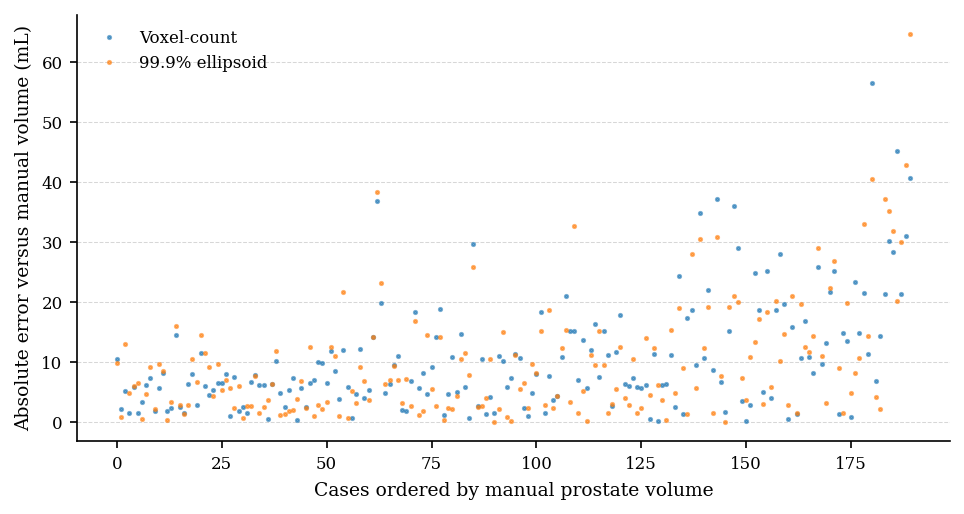

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 3.5))
positions = np.arange(len(analysis))
order = np.argsort(manual)

ax.plot(positions, voxel_abs_error[order], ".", markersize=3, alpha=0.6, label="Voxel-count")
ax.plot(
    positions,
    ellipsoid_abs_error[order],
    ".",
    markersize=3,
    alpha=0.6,
    label="99.9% ellipsoid",
)
ax.set_xlabel("Cases ordered by manual prostate volume")
ax.set_ylabel("Absolute error versus manual volume (mL)")
ax.legend(frameon=False)
ax.grid(True, axis="y", linestyle="--", linewidth=0.5, alpha=0.5)
fig.tight_layout()
plt.show()

 ## Compact conclusion inputs

 Negative `median_paired_error_delta_ml` and `matched_rank_biserial` values favor
 the 99.9% ellipsoid over direct voxel-count volume. The sensitivity rows quantify
 whether changing from percentile extents to exact min-max extents is material.

In [ ]:
print("All pairwise agreement statistics (second minus first)")
display(
    agreement[
        [
            "bias_ml",
            "bias_ci_lower_ml",
            "bias_ci_upper_ml",
            "bias_p",
            "bias_p_holm",
            "loa_lower_ml",
            "loa_upper_ml",
            "mae_ml",
            "rmse_ml",
            "pearson_r",
            "icc_a1",
        ]
    ]
)

print("Pearson correlation matrix")
display(pearson_matrix)

print("ICC(A,1) matrix")
display(icc_matrix)

print("Friedman omnibus test and Holm-adjusted Wilcoxon post-hoc tests")
display(omnibus.to_frame())
display(posthoc)

print("Primary paired absolute-error comparison")
display(primary_test.to_frame())

print("99.9% versus min-max sensitivity")
display(box_sensitivity.describe().T)

All pairwise agreement statistics (second minus first)


,bias_ml,bias_ci_lower_ml,bias_ci_upper_ml,bias_p,bias_p_holm,loa_lower_ml,loa_upper_ml,mae_ml,rmse_ml,pearson_r,icc_a1
99.9% ellipsoid minus Manual marksheet,-0.348119,-2.341753,1.645516,0.730895,0.730895,-27.653013,26.956775,9.851008,13.898719,0.934187,0.930505
Voxel-count volume minus Manual marksheet,-2.619683,-4.592816,-0.646550,0.009535,0.019070,-29.643785,24.404419,10.401184,13.998779,0.935506,0.932608
Voxel-count volume minus 99.9% ellipsoid,-2.271564,-3.272795,-1.270333,0.000013,0.000039,-15.984462,11.441333,5.573392,7.338369,0.982531,0.979681


Pearson correlation matrix


,Manual marksheet,99.9% ellipsoid,Voxel-count volume
Manual marksheet,1.000000,0.934187,0.935506
99.9% ellipsoid,0.934187,1.000000,0.982531
Voxel-count volume,0.935506,0.982531,1.000000


ICC(A,1) matrix


,Manual marksheet,99.9% ellipsoid,Voxel-count volume
Manual marksheet,1.000000,0.930505,0.932608
99.9% ellipsoid,0.930505,1.000000,0.979681
Voxel-count volume,0.932608,0.979681,1.000000


... (3 outputs left out)

Primary paired absolute-error comparison


,Primary paired absolute-error test
n,190.000000
voxel_mae_ml,10.401184
ellipsoid_999_mae_ml,9.851008
ellipsoid_closer_n,98.000000
equal_error_n,0.000000
median_paired_error_delta_ml,-0.193587
median_delta_ci_lower_ml,-1.325059
median_delta_ci_upper_ml,0.637482
wilcoxon_statistic,8248.000000
wilcoxon_p,0.277357


99.9% versus min-max sensitivity


,count,mean,std,min,25%,50%,75%,max
99.9% ellipsoid (mL),190.0,69.010828,35.525336,16.508846,44.041399,61.806712,84.614373,243.282563
Min-max ellipsoid (mL),190.0,73.742324,38.390592,17.307427,46.291370,65.809691,91.131224,264.864081
Min-max minus 99.9% (mL),190.0,4.731496,3.103525,0.693496,2.543119,3.984914,6.392062,21.581518
Min-max / 99.9%,190.0,1.065912,0.018538,1.021098,1.052446,1.065115,1.075925,1.139526
